# Aprendizado de Máquina

## Sistemas de recomendação

- Fábio Felsky
- Lemuel Manske
- Thiago Russi

Dataset: https://www.kaggle.com/datasets/arashnic/book-recommendation-dataset

## Artigos correlatos

- https://link.springer.com/article/10.1007/s40745-023-00474-4

## Objetivo

Desenvolver um algoritmo de recomendação para recomendar livros para usuários.

Entrada: usuário (ID), saída: livros recomendados.

## Escopo

### 1. Preparação e análise dos dados

- [x] Analisar a esparsidade do dataset e seu impacto na identificação de vizinhos.
- [x] Investigar estratégias de filtragem para selecionar usuários e livros com avaliações suficientes.
- [x] Diferenciar avaliações com nota zero da ausência de avaliação e definir como tratá-las.
- [x] Calcular a proporção de avaliações existentes em relação ao total de combinações possíveis entre usuários e livros.

### 2. Implementação e análise das recomendações

- [x] Implementar e comparar as estratégias User-based e Item-based.
- [x] Demonstrar como as recomendações são construídas, utilizando `.neighbors` e `.similar_books`.
- [x] Investigar o impacto da quantidade de avaliações de um usuário na qualidade das recomendações.
- [x] Comparar as condições em que cada estratégia apresenta melhores resultados.
- [x] Analisar a sobreposição entre as recomendações produzidas pelas duas estratégias.

### 3. Avaliação quantitativa

- [x] Separar avaliações conhecidas para verificar se os algoritmos conseguem recuperar livros bem avaliados pelos usuários.
- [x] Avaliar as recomendações utilizando Precision, Recall e F1-score.
- [x] Investigar a influência do parâmetro `k` (5, 10, 20, 50, etc.) nos resultados.
- [x] Plotar a variação de Precision, Recall e F1-score em função de `k`.

### 4. Avaliação qualitativa

- [X] Comparar as recomendações produzidas pelos algoritmos com recomendações disponíveis no [Goodreads](https://www.goodreads.com/).
- [X] Analisar a relevância e a coerência das recomendações geradas.

### 5. Discussão dos resultados

- [x] Discutir o impacto da esparsidade e da filtragem dos dados no desempenho dos algoritmos.
- [x] Evidenciar a dependência das avaliações existentes para inferir as preferências dos usuários.
- [x] Discutir as limitações das recomendações para usuários com poucas avaliações.
- [x] Identificar em quais cenários é mais adequado utilizar User-based ou Item-based.

## Entidades

**Livros**: ISBN, ano de publicação, título e autor.

**Usuários**: ID, localidade.

**Avaliações**: usuário *x*  livro.

## Propriedades do dataset

- 0 significa feedback implícito: usuário interagiu com o livro mas não deu uma nota

- 1-10 significa feedback explícito

## Desafios

> Como o algoritmo consegue descobrir que dois livros estão relacionados se não sabemos seus gêneros, assuntos ou sinopses?

## Estratégias

> O que o algoritmo deve procurar primeiro para fazer uma recomendação?

| Usuário | Livro A | Livro B | Livro C | Livro D |
|---|---|---|---|---|
| João | 10 | 2 | — | — |
| Maria | 10 | 2 | 10 | 2 |
| Ana | 9 | 7 | 2 | 9 |
| Pedro | 8 | 8 | 2 | 8 |
| Luiza | 7 | 9 | 2 | 9 |

### Filtragem baseada em livros (afinidade por item)

Procura livros parecidos entre si.

> João gostou do livro A mas não do B. Quais outros livros apresentam padrões de avaliação semelhantes aos de A?

**Recomendação:** Livro D, pois seu padrão de avaliações apresenta afinidade com o Livro A, de que João gostou.

### Filtragem baseada em usuários (afinidade por usuário)

Procura usuários parecidos entre si.

> João gostou do livro A mas não do B. Quais usuários possuem gostos parecidos com os dele? E quais outros livros essas pessoas gostaram?

**Recomendação:** Livro C, pois Maria possui avaliações idênticas às de João nos livros A e B e gostou do Livro C.

In [1]:
!pip install pandas numpy kagglehub scipy scikit-learn matplotlib

## Parte 1: Importar dataset e criar `DataFrames`

In [2]:
import kagglehub

from pathlib import Path

OUTPUT_DIR = Path("./kaggle/book-recommendation-dataset")

if not any(OUTPUT_DIR.iterdir()):
    path = Path(kagglehub.dataset_download("arashnic/book-recommendation-dataset", output_dir="./kaggle/book-recommendation-dataset"))
else:
    path = OUTPUT_DIR

BOOKS_PATH = path / "Books.csv"
RATINGS_PATH = path / "Ratings.csv"
USERS_PATH = path / "Users.csv"

/home/lkmliz/dev/notebooks/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
import csv

import pandas as pd

books = []
ratings = []
users = []

with open(BOOKS_PATH, newline='') as f:
  r = csv.reader(f, delimiter=',')
  books = list(r)

with open(RATINGS_PATH, newline='') as f:
  r = csv.reader(f, delimiter=',')
  ratings = list(r)

with open(USERS_PATH, newline='') as f:
  r = csv.reader(f, delimiter=',')
  users = list(r)

books_df = pd.DataFrame(books[1:], columns=books[0])
ratings_df = pd.DataFrame(ratings[1:], columns=ratings[0])
users_df = pd.DataFrame(users[1:], columns=users[0])

In [4]:
ratings_df.head()

,User-ID,ISBN,Book-Rating
0,276725,034545104X,0
1,276726,0155061224,5
2,276727,0446520802,0
3,276729,052165615X,3
4,276729,0521795028,6


## Parte 2: Organizar dataset

In [5]:
ratings_df["Book-Rating"] = pd.to_numeric(
    ratings_df["Book-Rating"],
    errors="coerce"
)

# Extrair ratings explícitos (0 = implícito)
explicit_ratings = ratings_df[ratings_df["Book-Rating"] > 0]

In [6]:
# Existem obras com múltiplos ISBNs?

def multiple_editions_ratio() -> float:
    books = books_df.drop_duplicates("ISBN").copy()

    books["work_id"] = (
        books["Book-Title"].str.strip().str.casefold()
        + " | "
        + books["Book-Author"].str.strip().str.casefold()
    )

    multiple_editions = books.groupby("work_id")["ISBN"].transform("nunique") > 1

    valid = explicit_ratings["ISBN"].isin(books["ISBN"])

    return explicit_ratings.loc[valid, "ISBN"].isin(
        books.loc[multiple_editions, "ISBN"]
    ).mean()

print(
    "Avaliações pertencentes a obras com múltiplos ISBNs:",
    f"{multiple_editions_ratio():.2%}"
)

Avaliações pertencentes a obras com múltiplos ISBNs: 36.02%


In [7]:
# Como existe uma grande quantidade de ISBNs "duplicados", vamos manter um canônico por obra

books = books_df.drop_duplicates("ISBN").copy()
books["work_id"] = (
    books["Book-Title"].str.strip().str.casefold()
    + " | "
    + books["Book-Author"].str.strip().str.casefold()
)
books["canonical_isbn"] = books.groupby("work_id")["ISBN"].transform("first")


isbn_map = books.set_index("ISBN")["canonical_isbn"]


books_df = (
    books.drop_duplicates("canonical_isbn")
    .drop(columns=["ISBN", "work_id"]) 
    .rename(columns={"canonical_isbn": "ISBN"})
)


ratings_df = ratings_df.copy()
ratings_df["ISBN"] = ratings_df["ISBN"].map(isbn_map).fillna(ratings_df["ISBN"])


explicit_ratings = explicit_ratings.copy()
explicit_ratings["ISBN"] = (
    explicit_ratings["ISBN"]
    .map(isbn_map)
    .fillna(explicit_ratings["ISBN"])
)

# Manter ambiente livre de variáveis temporárias
books = None
isbn_map = None

In [83]:
import pandas as pd
import numpy as np

from scipy.sparse import csr_matrix

def build_matrices(df):
  global M, T, M_ones, T_ones
  global user_x_ratings, book_x_ratings, user_to_idx
  global user_codes, user_ids, book_codes, book_isbns

  user_codes, user_ids = pd.factorize(df["User-ID"])
  book_codes, book_isbns = pd.factorize(df["ISBN"])

  M = csr_matrix(
    (
      df["Book-Rating"].to_numpy(dtype=float),
      (user_codes, book_codes)
    ),
    shape=(len(user_ids), len(book_isbns))
  )

  T = M.T.tocsr()

  M_ones = M.copy()
  M_ones.data[:] = 1

  T_ones = M_ones.T.tocsr()

  user_x_ratings = df \
    .groupby("User-ID") \
    .size() \
    .sort_values(ascending=False)
    
  book_x_ratings = df \
    .groupby("ISBN") \
    .size() \
    .sort_values(ascending=False)
    
  user_to_idx = {
    str(user_id): idx
    for idx, user_id in enumerate(user_ids)
  }

build_matrices(explicit_ratings)


def user_details(user_id):
  user_id = str(user_id)

  if user_id not in user_to_idx.keys():
    return {
      "ID": user_id,
      "Localidade": "Desconhecida",
    }

  user_idx = user_to_idx[user_id]
  user = users_df.iloc[user_idx]

  return {
    "ID": user_id,
    "Localidade": user["Location"],
  }


def book_details(isbn):
  isbn = str(isbn)

  if isbn not in book_info.index:
    return {
      "ISBN": isbn,
      "Título": "Desconhecido",
      "Autor": "Desconhecido",
    }

  book = book_info.loc[isbn]

  return {
    "ISBN": isbn,
    "Título": book["Book-Title"],
    "Autor": book["Book-Author"],
  }

# Map ISBN => title
books_by_isbn = books_df \
  .drop_duplicates(subset="ISBN") \
  .set_index("ISBN")["Book-Title"] \
  .to_dict()

# Map ISBN => author
author_by_isbn = books_df \
  .drop_duplicates(subset="ISBN") \
  .set_index("ISBN")["Book-Author"] \
  .to_dict()

# ISBNs
book_isbns = [
  book_isbn
  for book_isbn in book_isbns
]

In [9]:
print(M.shape) # Usuários, ISBNs
print(T.shape) # ISBNs, Usuários

(77805, 174216)
(174216, 77805)


In [10]:
preview = pd.DataFrame(
  M[:10, :10].toarray(),
  index=user_ids[:10],
  columns=book_isbns[:10]
)

print()
print('Matriz normal:')

display(preview.replace(0, float("nan")))

preview_T = pd.DataFrame(
  T[:10, :10].toarray(),
  index=book_isbns[:10],
  columns=user_ids[:10]
)

print()
print('Matriz transposta:')

display(preview_T.replace(0, float("nan")))


Matriz normal:


,0155061224,052165615X,0521795028,3257224281,0600570967,044023722X,342310538,0060517794,0671537458,0679776818
276726,5.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
276729,NaN,3.0,6.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
276736,NaN,NaN,NaN,8.0,NaN,NaN,NaN,NaN,NaN,NaN
276737,NaN,NaN,NaN,NaN,6.0,NaN,NaN,NaN,NaN,NaN
276744,NaN,NaN,NaN,NaN,NaN,7.0,NaN,NaN,NaN,NaN
276745,NaN,NaN,NaN,NaN,NaN,NaN,10.0,NaN,NaN,NaN
276747,NaN,NaN,NaN,NaN,NaN,NaN,NaN,9.0,9.0,8.0
276748,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
276751,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
276754,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Matriz transposta:


,276726,276729,276736,276737,276744,276745,276747,276748,276751,276754
0155061224,5.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
052165615X,NaN,3.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
0521795028,NaN,6.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3257224281,NaN,NaN,8.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
0600570967,NaN,NaN,NaN,6.0,NaN,NaN,NaN,NaN,NaN,NaN
044023722X,NaN,NaN,NaN,NaN,7.0,NaN,NaN,NaN,NaN,NaN
342310538,NaN,NaN,NaN,NaN,NaN,10.0,NaN,NaN,NaN,NaN
0060517794,NaN,NaN,NaN,NaN,NaN,NaN,9.0,NaN,NaN,NaN
0671537458,NaN,NaN,NaN,NaN,NaN,NaN,9.0,NaN,NaN,NaN
0679776818,NaN,NaN,NaN,NaN,NaN,NaN,8.0,NaN,NaN,NaN


## Parte 2.1: Entender dataset

,User-ID,ISBN,Book-Rating
0,276725,034545104X,0
1,276726,0155061224,5
2,276727,0446605239,0
3,276729,052165615X,3
4,276729,0521795028,6


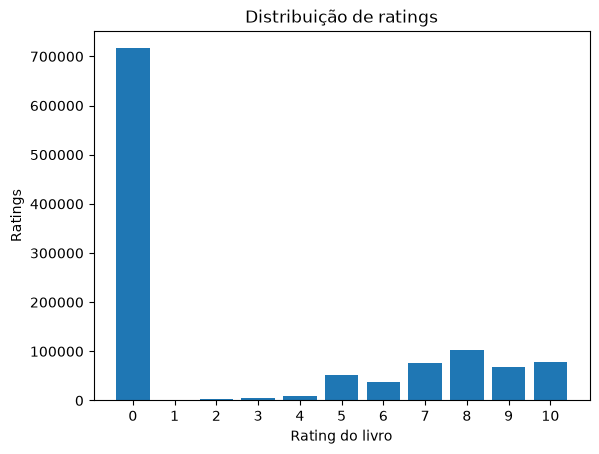

In [11]:
print()
display(ratings_df.head())


import matplotlib.pyplot as plt

print()

user_x_ratings_counts = ratings_df["Book-Rating"].value_counts().sort_index()

plt.bar(user_x_ratings_counts.index, user_x_ratings_counts.values)

plt.xlabel("Rating do livro")
plt.ylabel("Ratings")
plt.title("Distribuição de ratings")
plt.xticks(range(0, int(ratings_df["Book-Rating"].max()) + 1))
plt.show()

Podemos ver que a distribuição é irregular:
- Existem muitos feedbacks implícitos
- O restante é melhor distribuído, mas feedbacks ruins são poucos

In [12]:
print()
display(user_x_ratings.head())

print()
display(book_x_ratings.head())

User-ID
11676     8524
98391     5802
153662    1969
189835    1906
23902     1395
dtype: int64

ISBN
0316666343    707
0971880107    581
0385504209    494
0142001740    406
0312278586    393
dtype: int64

Mode: 1
Median: 1.0



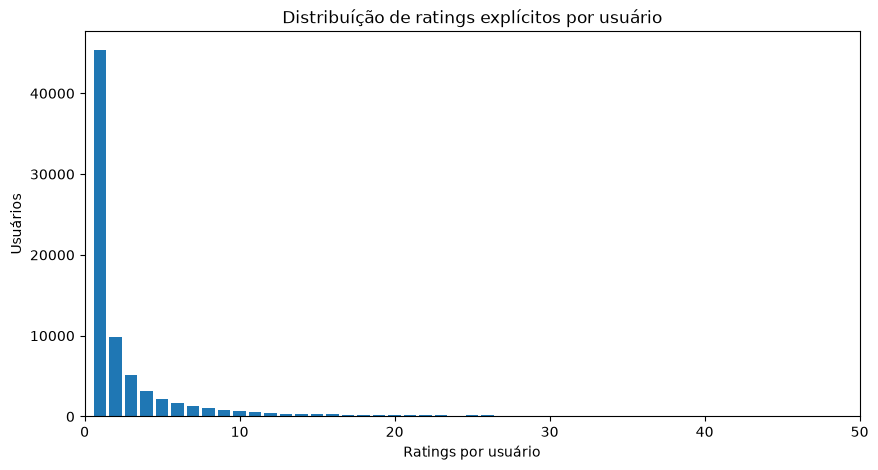

In [13]:
mode = user_x_ratings.mode()
print(f'Mode: {mode[0]}')

median = user_x_ratings.median()
print(f'Median: {median}')


import matplotlib.pyplot as plt

print()

user_x_ratings_counts = user_x_ratings \
  .value_counts() \
  .sort_index()

plt.figure(figsize=(10, 5))
plt.bar(user_x_ratings_counts.index, user_x_ratings_counts.values)

plt.xlim(0, 50)
plt.xlabel("Ratings por usuário")
plt.ylabel("Usuários")
plt.title("Distribuíção de ratings explícitos por usuário")
plt.show()

Podemos concluir que a grande maioria dos usuários só avaliou um único livro. Isso, teoricamente, é ruim para o propósito do trabalho, pois o sistema se baseia exclusivamente nos ratings, quer dizer, uma única avaliação é muito pouco para deduzir as preferências do usuário, impactando na qualidade da recomendação. Mais para frente vamos explorar isso mais a fundo.

Com isso, precisamos visualizar qual a distribuição de ratings por livro além dos usuários para chegar numa conclusão mais apropriada.

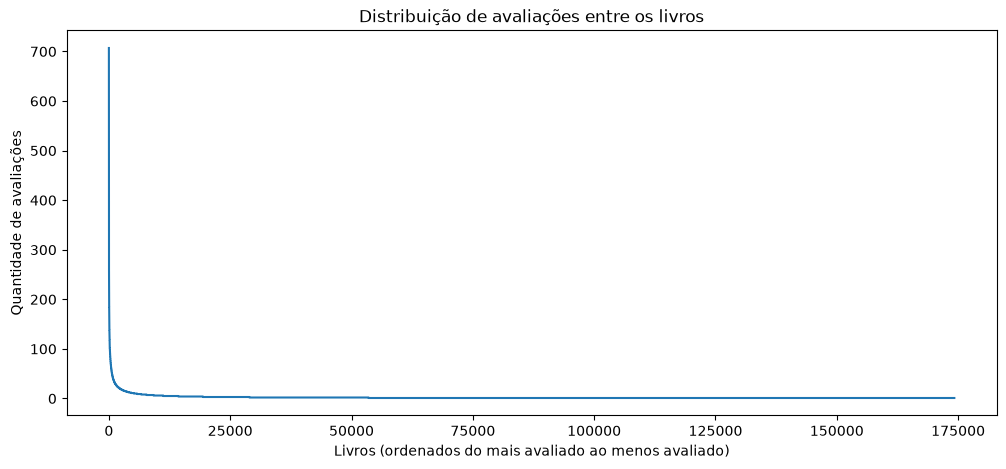

In [14]:
import matplotlib.pyplot as plt

book_counts = (
  explicit_ratings
  .groupby("ISBN")
  .size()
  .sort_values(ascending=False)
)

plt.figure(figsize=(12, 5))

plt.plot(range(1, len(book_counts) + 1), book_counts.values)

plt.xlabel("Livros (ordenados do mais avaliado ao menos avaliado)")
plt.ylabel("Quantidade de avaliações")
plt.title("Distribuição de avaliações entre os livros")
plt.show()

book_counts = None

Agora sabemos que as avaliações também estão concentradas em poucos títulos.

Para filtragem baseada em usuário, isso gera dois cenários:

- Usuários que avaliaram livros populares: têm maior probabilidade de encontrar outros usuários que avaliaram os mesmos livros. Entretanto, compartilhar apenas uma avaliação não é suficiente para estimar **similaridade com confiança**.
- Usuários que avaliaram livros pouco populares: têm menor probabilidade de encontrar outros usuários com avaliações em comum, dificultando a identificação de vizinhos.

Para filtragem baseada em livros, a consequência é mais direta: livros populares tendem a ter estimativas de similaridade mais bem fundamentadas, enquanto livros pouco avaliados podem ficar praticamente isolados, ou seja, não serem recomendados.

In [15]:
def max_overlap(matrix, batch_size=256):
  maximums = np.zeros(matrix.shape[0], dtype=np.int32)

  for start in range(0, matrix.shape[0], batch_size):
    end = min(start + batch_size, matrix.shape[0])

    overlap = matrix[start:end] @ matrix.T

    # Ignorar a comparação de cada entidade consigo mesma
    overlap = overlap.tolil()

    for local_idx, global_idx in enumerate(range(start, end)):
      overlap[local_idx, global_idx] = 0

    overlap = overlap.tocsr()
    overlap.eliminate_zeros()

    for local_idx in range(end - start):
      row = overlap.getrow(local_idx)

      if row.nnz:
        maximums[start + local_idx] = row.data.max()

  return maximums

In [16]:
user_max_overlap = max_overlap(M_ones)
book_max_overlap = max_overlap(T_ones)

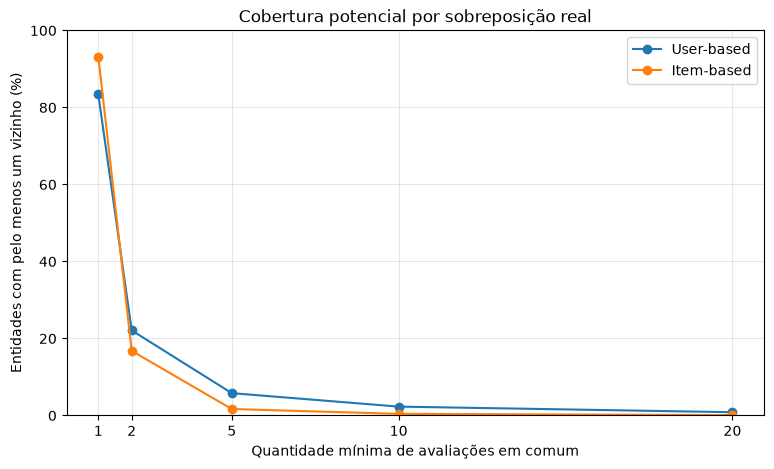

In [17]:
KERNELS = [1, 2, 5, 10, 20]

results = pd.DataFrame({
    "Min. overlap": KERNELS,
    "Usuários (%)": [
        100 * np.mean(user_max_overlap >= k)
        for k in KERNELS
    ],
    "Livros (%)": [
        100 * np.mean(book_max_overlap >= k)
        for k in KERNELS
    ]
})


import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    results["Min. overlap"],
    results["Usuários (%)"],
    marker="o",
    label="User-based"
)

plt.plot(
    results["Min. overlap"],
    results["Livros (%)"],
    marker="o",
    label="Item-based"
)

plt.xlabel("Quantidade mínima de avaliações em comum")
plt.ylabel("Entidades com pelo menos um vizinho (%)")
plt.title("Cobertura potencial por sobreposição real")
plt.xticks(KERNELS)
plt.ylim(0, 100)
plt.legend()
plt.grid(alpha=0.3)

plt.show()

A análise da sobreposição entre avaliações revelou que, embora exista uma conectividade relativamente elevada entre usuários e livros, essa conectividade é sustentada predominantemente por relações de baixa sobreposição. A maioria das entidades possui ao menos um vizinho potencial, mas poucas apresentam vizinhos com múltiplas avaliações compartilhadas. Essa característica limita a confiabilidade das estimativas de similaridade utilizadas pelos algoritmos de filtragem colaborativa baseados em kNN.

## Então?

Até agora, os resultados demonstraram ser pouco favoráveis ao kNN. Embora isso seja interpretado como ruim para o propósito do trabalho, podemos ver o outro lado: como explorar os limites do kNN? Como podemos garantir boas recomendações embora tudo isso? É possível?

## Parte 3: Preparando algoritmos

In [18]:
import numpy as np

from sklearn.neighbors import NearestNeighbors

# Essa é a principal função do projeto
# Ela que seleciona os vizinhos, e possui vários hiperparâmetros para testarmos possibilidades
def select_neighbors(
    model,
    matrix,
    binary_matrix,
    index,
    k=20, # Quantidade máxima de vizinhos mais similares para retornar. Podem ser menos por causa dos filtros
    candidate_pool=100, # Quantos candidatos pré-selecionar. Proporcional com o custo computacional
    min_overlap=1, # Mínimo de avaliações em comum
    shrinkage=0.0, # Quanto penalizar uma similaridade muito otimista
    metric="cosine",
    exclude=None,
):
  assert metric in {"cosine", "euclidean"}
  # assert k > 0

  exclude = set() if exclude is None else set(exclude)
  exclude.add(index) # Não recomendar o próprio candidato

  # Buscar candidatos antes de aplicar os filtros
  pool_size = (
    candidate_pool
    if k == -1
    else max(k, candidate_pool)
  )

  n_candidates = min(
    pool_size + len(exclude),
    matrix.shape[0],
  )

  dists, idxs = model.kneighbors(
    matrix.getrow(index),
    n_neighbors=n_candidates,
  )

  source = binary_matrix.getrow(index)
  neighbors = []

  for idx, dist in zip(idxs[0], dists[0]):
    idx = int(idx)

    if idx in exclude:
      continue

    # Converter distância para similaridade, respeitando se for cos. ou euclid.
    if metric == "cosine":
      similarity = max(0.0, 1.0 - float(dist))
    elif metric == "euclidean":
      similarity = 1.0 / (1.0 + float(dist))

    if similarity <= 0:
      continue

    # Quantidade de avaliações compartilhadas
    target = binary_matrix.getrow(idx)

    overlap = np.intersect1d(
      source.indices,
      target.indices,
      assume_unique=True,
    ).size

    if overlap < min_overlap:
      continue

    # Penalizar relações com pouca sobreposição (muito otimistas), pois muito provavelmente é uma recomendação precipitada
    if shrinkage > 0:
      similarity *= overlap / (overlap + shrinkage)

    neighbors.append((idx, similarity))

  # Reordenar após a regularização
  neighbors.sort(key=lambda item: item[1], reverse=True)

  return neighbors if k == -1 else neighbors[:k]

### O que é `min_overlap`?

Esse parâmetro define a quantidade mínima de avaliações em comum para considerar vizinhos.

| Usuário |	Livro A |	Livro B |	Livro C |
| --- | --- | --- | --- |
| Alice |	9 |	8 |	— |
| Bob |	8 |	7 |	10 |
| Carlos |	9 |	— |	6 |

Para filtragem baseada em usuários, por exemplo:

- Alice x Bob: `overlap` = 2 (livros A e B).
- Alice x Carlos: `overlap` = 1 (livro A).

Para filtragem baseeada em livros:

- Livro A x Livro B: `overlap` = 2 (Alice e Bob).

###  O que é `shrinkage`?

- https://en.wikipedia.org/wiki/Shrinkage_(statistics)

Imagine:

| Neighbor | Similarity | Livros em comum |
| --- | --- | --- |
| Alice | .95 | 1 |
| Bob | .88 | 20 |

Aqui, embora Bob tenha uma similaridade mais baixa, é muito mais provável que a recomendação que parte de Bob seja mais segura que de Alice para um usuário X.

Quanto maior a sobreposição, maior tende a ser a confiança que podemos depositar na estimativa de similaridade. Mas isso não significa necessariamente que a chance de acertar a recomendação seja muito maior.

Então, o shrinkage é o parâmetro de regularização: uma técnica que reduz a similaridade estimada quando ela foi calculada com poucas observações em comum.

In [19]:
from sklearn.neighbors import NearestNeighbors

from collections import defaultdict
from dataclasses import dataclass, field
from typing import Protocol


@dataclass
class Recommendation:
  isbn: str
  score: float


@dataclass
class FilterResult:
  user_id: str
  recommendations: list[Recommendation]
  candidates: set[str] = field(default_factory=set)


class Filter(Protocol):
  def recommend(self, user_id: str, n: int) -> FilterResult:
    ...


@dataclass
class UserBasedFilterResult(FilterResult):
  neighbors: list[tuple[str, float]] = field(default_factory=list)


@dataclass
class BookBasedFilterResult(FilterResult):
  similar_books: dict[str, list[tuple[str, float]]] = field(
    default_factory=dict
  )

from collections import defaultdict


class UserBasedFilter(Filter):
  def __init__(
    self,
    metric="cosine",
    algorithm="brute",
    k=20,
    candidate_pool=100,
    min_overlap=1,
    shrinkage=0.0,
  ):
    self.metric = metric
    self.k = k
    self.candidate_pool = candidate_pool
    self.min_overlap = min_overlap
    self.shrinkage = shrinkage

    self.M = M.tocsr()
    self.M_ones = M_ones.tocsr()
      
    self.user_means = (
      np.asarray(self.M.sum(axis=1)).ravel()
      / np.maximum(self.M.getnnz(axis=1), 1)
    )

    self.model = NearestNeighbors(
      metric=metric,
      algorithm=algorithm,
    )
    self.model.fit(self.M)

  def recommend(self, user_id: str, n: int) -> UserBasedFilterResult:
    user_idx = user_to_idx[user_id]

    user_ratings = self.M.getrow(user_idx)
    rated_books = set(user_ratings.indices)

    neighbors = select_neighbors(
      model=self.model,
      matrix=self.M,
      binary_matrix=self.M_ones,
      index=user_idx,
      k=self.k,
      candidate_pool=self.candidate_pool,
      min_overlap=self.min_overlap,
      shrinkage=self.shrinkage,
      metric=self.metric,
    )

    scores = defaultdict(float)
    weights = defaultdict(float)

    for idx, similarity in neighbors:
      neighbor_ratings = self.M.getrow(idx)

      for book_idx, rating in zip(
        neighbor_ratings.indices,
        neighbor_ratings.data,
      ):
        book_idx = int(book_idx)

        if book_idx in rated_books:
          continue

        contribution = float(rating) / 10

        scores[book_idx] += similarity * contribution
        weights[book_idx] += similarity

    ranking = sorted(
      scores,
      key=scores.get,
      reverse=True,
    )

    recommendations = []

    for idx in ranking:
      isbn = str(book_isbns[idx])

      if books_by_isbn.get(isbn) is None:
        continue

      recommendations.append(
        Recommendation(
          isbn=isbn,
          score=float(scores[idx]),
        )
      )

      if len(recommendations) >= n:
        break

    candidates = {
      str(book_isbns[idx])
      for idx in scores
    }

    return UserBasedFilterResult(
      user_id=user_id,
      recommendations=recommendations,
      candidates=candidates,
      neighbors=[
        (str(user_ids[idx]), float(similarity))
        for idx, similarity in neighbors
      ],
    )


class BookBasedFilter(Filter):
  def __init__(
    self,
    metric="cosine",
    algorithm="brute",
    k=20,
    min_rating=7,
    candidate_pool=100,
    min_overlap=1,
    shrinkage=0.0,
  ):
    self.metric = metric
    self.k = k
    self.min_rating = min_rating
    self.candidate_pool = candidate_pool
    self.min_overlap = min_overlap
    self.shrinkage = shrinkage

    self.M = M.tocsr()
    self.MT = T.tocsr()
    self.T_ones = T_ones.tocsr()

    self.model = NearestNeighbors(
      metric=metric,
      algorithm=algorithm,
    )
    self.model.fit(self.MT)

  def recommend(self, user_id: str, n: int) -> BookBasedFilterResult:
    user_idx = user_to_idx[user_id]

    user_ratings = self.M.getrow(user_idx)
    rated_books = set(user_ratings.indices)

    liked_books = [
      (int(idx), float(rating))
      for idx, rating in zip(
        user_ratings.indices,
        user_ratings.data,
      )
      if rating >= self.min_rating
    ]

    scores = defaultdict(float)
    weights = defaultdict(float)
    contributions = defaultdict(list)

    for book_idx, rating in liked_books:
      neighbors = select_neighbors(
        model=self.model,
        matrix=self.MT,
        binary_matrix=self.T_ones,
        index=book_idx,
        k=self.k,
        candidate_pool=self.candidate_pool,
        min_overlap=self.min_overlap,
        shrinkage=self.shrinkage,
        metric=self.metric,
        exclude=rated_books,
      )

      for idx, similarity in neighbors:
        scores[idx] += similarity * (rating / 10)
        weights[idx] += similarity

        contributions[idx].append(
          (str(book_isbns[book_idx]), similarity)
        )

    ranking = sorted(
      scores,
      key=scores.get,
      reverse=True,
    )

    recommendations = []
    similar_books = {}

    for idx in ranking:
      isbn = str(book_isbns[idx])

      if books_by_isbn.get(isbn) is None:
        continue

      recommendations.append(
        Recommendation(
          isbn=isbn,
          score=float(scores[idx]),
        )
      )

      similar_books[isbn] = sorted(
        contributions[idx],
        key=lambda item: item[1],
        reverse=True,
      )

      if len(recommendations) >= n:
        break

    candidates = {
      str(book_isbns[idx])
      for idx in scores
    }

    return BookBasedFilterResult(
      user_id=user_id,
      recommendations=recommendations,
      candidates=candidates,
      similar_books=similar_books,
    )

# Parte 4: Análises

In [20]:
def explain_recommendations(user_id, models, n=5):
  user_id = str(user_id)
  explanations = {}

  for name, model in models.items():
    result = model.recommend(user_id, n=n)

    explanation = {
      "recommendations": pd.DataFrame([
        {
          "isbn": rec.isbn,
          "title": books_by_isbn.get(rec.isbn, "Desconhecido"),
          "score": rec.score,
        }
        for rec in result.recommendations
      ]),
    }

    if isinstance(result, UserBasedFilterResult):
      explanation["neighbors"] = pd.DataFrame(
        result.neighbors,
        columns=["user_id", "similarity"],
      )

    elif isinstance(result, BookBasedFilterResult):
      explanation["contributions"] = {
        rec.isbn: pd.DataFrame(
          [
            {
              "source_isbn": source,
              "source_title": books_by_isbn.get(source, source),
              "similarity": similarity,
            }
            for source, similarity
            in result.similar_books.get(rec.isbn, [])
          ]
        )
        for rec in result.recommendations
      }

    explanations[name] = explanation

  return explanations

In [21]:
import requests

from PIL import Image
from io import BytesIO
from functools import lru_cache

@lru_cache(maxsize=100)
def load_book_cover(isbn):
  url = f"https://covers.openlibrary.org/b/isbn/{isbn}-M.jpg?default=false"

  try:
    response = requests.get(url, timeout=5)
    response.raise_for_status()

    image = Image.open(BytesIO(response.content))
    return image.convert("RGB")
  except Exception:
    return None

In [22]:
def book_cover(isbn):
  cover = load_book_cover(str(isbn))

  if cover is None:
    return ""

  buffer = BytesIO()
  cover.save(buffer, format="JPEG")
  encoded = base64.b64encode(buffer.getvalue()).decode()

  return f'<img src="data:image/jpeg;base64,{encoded}">'

In [23]:
import numpy as np
import pandas as pd

# Separar o dataset para medir capacidade de generalização

def split_ratings(df = explicit_ratings, min_positive_rating: int = 7):
  df = df.copy().reset_index(drop=True)

  df["User-ID"] = df["User-ID"].astype(str)
  df["ISBN"] = df["ISBN"].astype(str)

  user_counts = df.groupby("User-ID").size()

  positive = df[df["Book-Rating"] >= min_positive_rating]
  positive_counts = positive.groupby("User-ID").size()

  eligible = user_counts.index[
    (user_counts >= 3)
    & (positive_counts.reindex(user_counts.index, fill_value=0) >= 2)
  ]

  rng = np.random.default_rng(42) # Fixar a seed para não tornar isso um bias

  validation_idx = []
  test_idx = []

  for _, group in positive[
    positive["User-ID"].isin(eligible)
  ].groupby("User-ID"):

    selected = rng.choice(
      group.index.to_numpy(),
      size=2,
      replace=False
    )

    validation_idx.append(int(selected[0]))
    test_idx.append(int(selected[1]))

  validation = df.loc[validation_idx].copy()
  test = df.loc[test_idx].copy()

  train = df.drop(
    index=validation_idx + test_idx
  ).copy()

  return train, validation, test

## Parte 4.1: Análise quantitativa

O quão bom são as recomendações ao analisar o relacionamento dos vizinhos?

In [24]:
def evaluate(model: Filter, test: pd.DataFrame, n: int = 10):
  results = []

  for user_id, isbn in zip(test["User-ID"], test["ISBN"]):
    user_id, isbn = str(user_id), str(isbn)

    result = model.recommend(user_id, n)
    recommendations = [rec.isbn for rec in result.recommendations]

    rank = recommendations.index(isbn) + 1 if isbn in recommendations else None

    results.append({
      "user_id": user_id,
      "isbn": isbn,
      "candidate_hit": isbn in result.candidates,
      "ranking_hit": rank is not None,
      "candidate_count": len(result.candidates),
      "recommendation_count": len(recommendations),
      "ndcg": 1 / np.log2(rank + 1) if rank is not None else 0.0,
    })

  details = pd.DataFrame(results)

  hit_rate = details["ranking_hit"].mean()
    
  recovered = details[details["candidate_hit"]]

  metrics = {
    "CandidateRecall": float(details["candidate_hit"].mean()),
    f"HitRate@{n}": float(hit_rate),
    f"NDCG@{n}": float(details["ndcg"].mean()),
    f"Precision@{n}": float(hit_rate / n),
    "Coverage": float((details["recommendation_count"] > 0).mean()),
    "AvgCandidates": float(details["candidate_count"].mean()),
    "RankingEfficiency": recovered["ranking_hit"].mean(),
  }

  return metrics, details

| Métrica | O que mede |
| --- | --- |
| CandidateRecall | Se o livro relevante está entre os candidatos gerados |
| HitRate@10 | Se o livro relevante aparece no Top 10 |
| NDCG@10 | Se aparece no Top 10, dando mais valor às primeiras posições |
| Precision@10 | Proporção das 10 posições ocupadas pelo livro relevante |
| Coverage | Proporção de avaliações para as quais o modelo produz pelo menos uma recomendação |
| AvgCandidates	| Quantidade média de candidatos gerados por avaliação |
| Ranking Efficiency | Frequência que um livro recuperado aparece no Top 10 |

- https://en.wikipedia.org/wiki/Discounted_cumulative_gain

In [25]:
from sklearn.model_selection import ParameterGrid

def grid_search(filter_class, validation, param_grid, n=10, **fixed_params):
  results = []
  details = []

  for params in ParameterGrid(param_grid):
    model = filter_class(
      metric="cosine",
      algorithm="brute",
      **fixed_params,
      **params,
    )

    metrics, details_ = evaluate(model, validation, n=n)

    results.append({
      "model": filter_class.__name__,
      **fixed_params,
      **params,
      **metrics,
    })

    details.append(details_)

  results = pd.DataFrame(results).sort_values(
    [f"NDCG@{n}", f"HitRate@{n}"],
    ascending=False,
  )

  details = [details[i] for i in results.index]

  return results.reset_index(drop=True), details

In [26]:
train_df, validation_df, test_df = split_ratings()

test_sample = test_df.sample(n=100, random_state=42)
validation_sample = validation_df.sample(n=100, random_state=42)

build_matrices(train_df)

In [27]:
PARAM_GRID = {
    "k": [2, 20, 50, 100],
    "candidate_pool": [100, 300, 500, 1000],
    "min_overlap": [1, 2, 5],
    "shrinkage": [0.0, 5.0],
}

user_results, _ = grid_search(
    UserBasedFilter,
    validation_sample,
    PARAM_GRID,
)

book_results, _ = grid_search(
    BookBasedFilter,
    validation_sample,
    PARAM_GRID,
    min_rating=5,
)

display(user_results.head(10))
display(book_results.head(10))

,model,candidate_pool,k,min_overlap,shrinkage,CandidateRecall,HitRate@10,NDCG@10,Precision@10,Coverage,AvgCandidates,RankingEfficiency
0,UserBasedFilter,100,100,1,0.0,0.22,0.04,0.036309,0.004,0.87,3280.34,0.181818
1,UserBasedFilter,100,100,1,5.0,0.22,0.04,0.036309,0.004,0.87,3280.34,0.181818
2,UserBasedFilter,300,100,1,0.0,0.22,0.04,0.036309,0.004,0.87,3280.32,0.181818
3,UserBasedFilter,300,100,1,5.0,0.23,0.04,0.036309,0.004,0.88,3326.27,0.173913
4,UserBasedFilter,500,100,1,0.0,0.22,0.04,0.036309,0.004,0.87,3280.34,0.181818
5,UserBasedFilter,500,100,1,5.0,0.24,0.04,0.036309,0.004,0.89,3378.36,0.166667
6,UserBasedFilter,1000,100,1,0.0,0.22,0.04,0.036309,0.004,0.87,3280.35,0.181818
7,UserBasedFilter,1000,100,1,5.0,0.26,0.04,0.036309,0.004,0.89,3532.56,0.153846
8,UserBasedFilter,100,50,1,5.0,0.16,0.04,0.032619,0.004,0.84,2332.40,0.250000
9,UserBasedFilter,300,50,1,5.0,0.17,0.04,0.032619,0.004,0.87,2356.83,0.235294


,model,min_rating,candidate_pool,k,min_overlap,shrinkage,CandidateRecall,HitRate@10,NDCG@10,Precision@10,Coverage,AvgCandidates,RankingEfficiency
0,BookBasedFilter,5,300,20,1,5.0,0.07,0.06,0.043175,0.006,0.88,162.69,0.857143
1,BookBasedFilter,5,300,20,2,5.0,0.07,0.06,0.043175,0.006,0.82,59.90,0.857143
2,BookBasedFilter,5,300,50,1,5.0,0.07,0.06,0.043175,0.006,0.88,389.10,0.857143
3,BookBasedFilter,5,300,50,2,5.0,0.07,0.06,0.043175,0.006,0.82,94.45,0.857143
4,BookBasedFilter,5,300,100,1,5.0,0.08,0.06,0.043175,0.006,0.88,733.87,0.750000
5,BookBasedFilter,5,300,100,2,5.0,0.07,0.06,0.043175,0.006,0.82,116.93,0.857143
6,BookBasedFilter,5,500,20,1,5.0,0.08,0.06,0.043175,0.006,0.88,162.20,0.750000
7,BookBasedFilter,5,500,20,2,5.0,0.08,0.06,0.043175,0.006,0.82,69.18,0.750000
8,BookBasedFilter,5,500,50,1,5.0,0.08,0.06,0.043175,0.006,0.88,388.72,0.750000
9,BookBasedFilter,5,500,50,2,5.0,0.08,0.06,0.043175,0.006,0.82,109.24,0.750000


User-based
Menor HitRate: 0.00%
Maior HitRate: 4.00%
HitRate médio: 1.35%
Amplitude: 4.00%

Item-based
Menor HitRate: 2.00%
Maior HitRate: 6.00%
HitRate médio: 4.35%
Amplitude: 4.00%



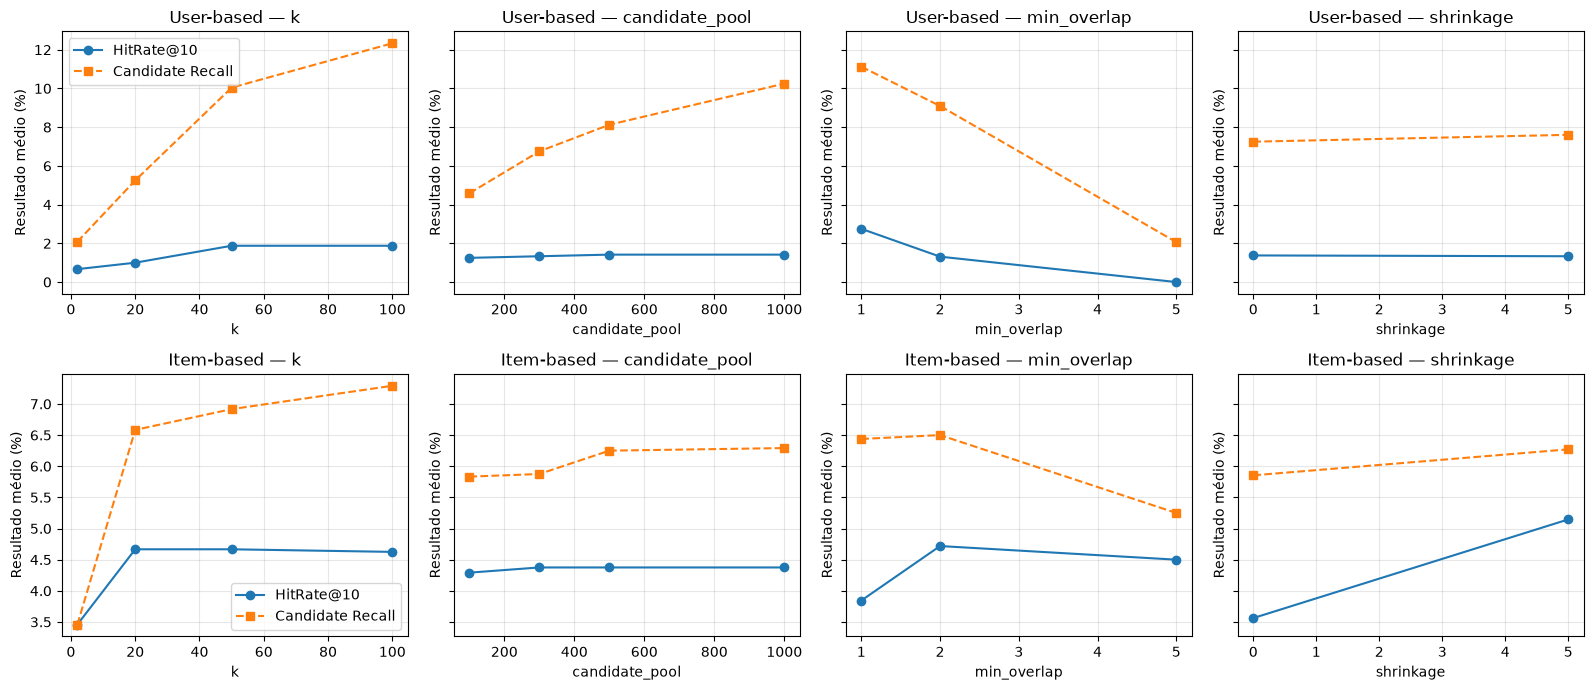

In [28]:
import matplotlib.pyplot as plt

params = ["k", "candidate_pool", "min_overlap", "shrinkage"]

fig, axes = plt.subplots(2, 4, figsize=(16, 7), sharey="row")

for row, (name, results) in enumerate([
  ("User-based", user_results),
  ("Item-based", book_results),
]):
  for col, param in enumerate(params):
    ax = axes[row, col]

    grouped = results.groupby(param)[
      ["HitRate@10", "CandidateRecall"]
    ].mean() * 100

    ax.plot(
      grouped.index,
      grouped["HitRate@10"],
      "o-",
      label="HitRate@10",
    )

    ax.plot(
      grouped.index,
      grouped["CandidateRecall"],
      "s--",
      label="Candidate Recall",
    )

    ax.set_title(f"{name} — {param}")
    ax.set_xlabel(param)
    ax.set_ylabel("Resultado médio (%)")
    ax.grid(alpha=0.3)

    if col == 0:
      ax.legend()

for name, results in [
  ("User-based", user_results),
  ("Item-based", book_results),
]:
  hit = results["HitRate@10"]

  print(name)
  print(f"Menor HitRate: {hit.min():.2%}")
  print(f"Maior HitRate: {hit.max():.2%}")
  print(f"HitRate médio: {hit.mean():.2%}")
  print(f"Amplitude: {(hit.max() - hit.min()):.2%}")
  print()

plt.tight_layout()
plt.show()

Com base nos resultados acima, a mudança dos hiperparâmetros não parece melhorar os resultados, ou seja, continuar ajustando eles é ineficiente.

No `UserBasedFilter`, podemos chegar na conclusão que o rankeamento neste modelo é uma das causas dos resultados ruins (vide Hit e NDCG). Além disso, a geração de candidatos também é ruim, pois, em média, temos muitos candidatos gerados, mas o aproveitamento está bem baixo.

Em `ItemBasedFilter`, o rankeamento está substancialmente melhor, mas a geração de candidatos também está ruim; não tanto quanto no anterior, mas ruim.

Em resumo, o `UserBasedFilter` recupera mais livros relevantes, mas precisa escolher apenas 10 entre milhares. O `ItemBasedFilter` recupera poucos livros relevantes, mas parece conseguir posicioná-los bem quando estão disponíveis.  O `candidade_pool` em especial, poderia ser ajustado para cobrir todo o dataset, mas, como vimos, isso também não iria ajudar nos resultados.

### Esparsidade

Como a esparsidade impacta nos resultados?

In [65]:
def filter_ratings(df = explicit_ratings, min_book_counts: int = 10, min_user_counts: int = 10):
  filtered_df = df.copy()

  while True:
    previous_size = len(filtered_df)

    user_counts = filtered_df.groupby("User-ID")["ISBN"].transform("size")
    book_counts = filtered_df.groupby("ISBN")["User-ID"].transform("size")

    filtered_df = filtered_df[
      (user_counts >= min_user_counts) & (book_counts >= min_book_counts)
    ].copy()

    if len(filtered_df) == previous_size:
      break

  return filtered_df

In [32]:
filtered_df = filter_ratings()

train_df, validation_df, test_df = split_ratings(filtered_df)

test_sample = test_df.sample(n=100, random_state=42)
validation_sample = validation_df.sample(n=100, random_state=42)

build_matrices(train_df)

In [33]:
PARAM_GRID = {
    "k": [2, 20, 50, 100],
    "candidate_pool": [100, 300, 500, 1000],
    "min_overlap": [1, 2, 5],
    "shrinkage": [0.0, 5.0],
}

user_results, _ = grid_search(
    UserBasedFilter,
    validation_sample,
    PARAM_GRID,
)

book_results, _ = grid_search(
    BookBasedFilter,
    validation_sample,
    PARAM_GRID,
    min_rating=5,
)

display(user_results.head(10))
display(book_results.head(10))

,model,candidate_pool,k,min_overlap,shrinkage,CandidateRecall,HitRate@10,NDCG@10,Precision@10,Coverage,AvgCandidates,RankingEfficiency
0,UserBasedFilter,300,100,1,5.0,0.89,0.07,0.035759,0.007,1.0,1871.99,0.078652
1,UserBasedFilter,100,100,1,0.0,0.82,0.07,0.033511,0.007,1.0,1416.43,0.085366
2,UserBasedFilter,300,100,1,0.0,0.82,0.07,0.033511,0.007,1.0,1416.38,0.085366
3,UserBasedFilter,500,100,1,0.0,0.82,0.07,0.033511,0.007,1.0,1416.38,0.085366
4,UserBasedFilter,1000,100,1,0.0,0.82,0.07,0.033511,0.007,1.0,1416.38,0.085366
5,UserBasedFilter,300,100,2,5.0,0.90,0.07,0.033212,0.007,1.0,1858.85,0.077778
6,UserBasedFilter,500,100,1,5.0,0.89,0.07,0.031376,0.007,1.0,1894.90,0.078652
7,UserBasedFilter,1000,100,1,5.0,0.89,0.07,0.031376,0.007,1.0,1899.23,0.078652
8,UserBasedFilter,300,50,1,5.0,0.81,0.07,0.029485,0.007,1.0,1579.68,0.086420
9,UserBasedFilter,500,50,1,5.0,0.81,0.07,0.029485,0.007,1.0,1579.68,0.086420


,model,min_rating,candidate_pool,k,min_overlap,shrinkage,CandidateRecall,HitRate@10,NDCG@10,Precision@10,Coverage,AvgCandidates,RankingEfficiency
0,BookBasedFilter,5,100,50,5,0.0,0.29,0.11,0.061359,0.011,1.0,225.42,0.379310
1,BookBasedFilter,5,100,20,5,0.0,0.23,0.11,0.059377,0.011,1.0,146.42,0.478261
2,BookBasedFilter,5,300,20,5,0.0,0.23,0.11,0.058112,0.011,1.0,153.72,0.478261
3,BookBasedFilter,5,500,20,5,0.0,0.23,0.11,0.057992,0.011,1.0,154.61,0.478261
4,BookBasedFilter,5,100,100,5,0.0,0.30,0.10,0.057839,0.010,1.0,260.29,0.333333
5,BookBasedFilter,5,1000,20,5,0.0,0.23,0.10,0.054957,0.010,1.0,155.03,0.434783
6,BookBasedFilter,5,100,20,1,5.0,0.37,0.11,0.052468,0.011,1.0,313.30,0.297297
7,BookBasedFilter,5,100,20,2,5.0,0.38,0.11,0.052468,0.011,1.0,307.33,0.289474
8,BookBasedFilter,5,300,20,1,5.0,0.37,0.11,0.052468,0.011,1.0,312.30,0.297297
9,BookBasedFilter,5,300,20,2,5.0,0.38,0.11,0.052468,0.011,1.0,307.46,0.289474


User-based
Menor HitRate: 2.00%
Maior HitRate: 7.00%
HitRate médio: 5.20%
Amplitude: 5.00%

Item-based
Menor HitRate: 5.00%
Maior HitRate: 11.00%
HitRate médio: 8.34%
Amplitude: 6.00%



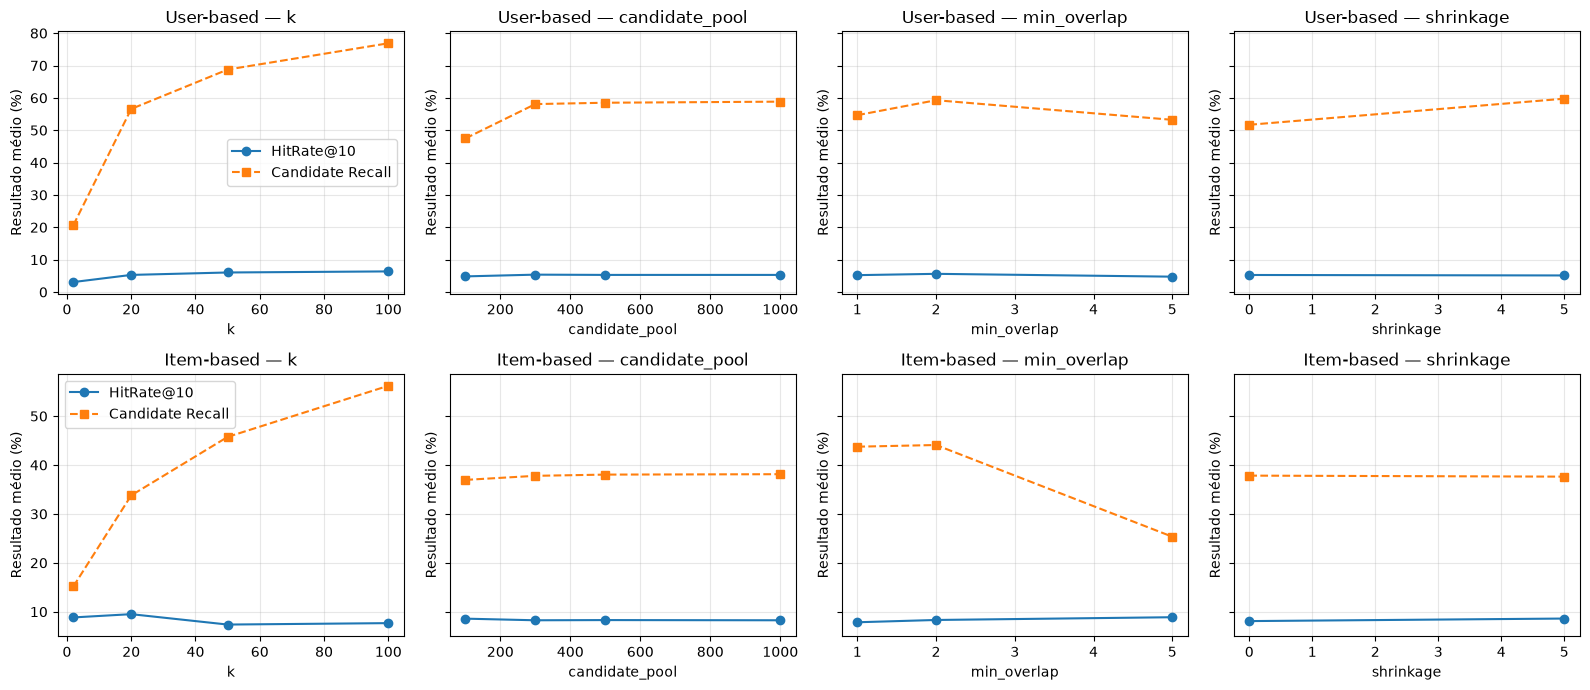

In [34]:
import matplotlib.pyplot as plt

params = ["k", "candidate_pool", "min_overlap", "shrinkage"]

fig, axes = plt.subplots(2, 4, figsize=(16, 7), sharey="row")

for row, (name, results) in enumerate([
  ("User-based", user_results),
  ("Item-based", book_results),
]):
  for col, param in enumerate(params):
    ax = axes[row, col]

    grouped = results.groupby(param)[
      ["HitRate@10", "CandidateRecall"]
    ].mean() * 100

    ax.plot(
      grouped.index,
      grouped["HitRate@10"],
      "o-",
      label="HitRate@10",
    )

    ax.plot(
      grouped.index,
      grouped["CandidateRecall"],
      "s--",
      label="Candidate Recall",
    )

    ax.set_title(f"{name} — {param}")
    ax.set_xlabel(param)
    ax.set_ylabel("Resultado médio (%)")
    ax.grid(alpha=0.3)

    if col == 0:
      ax.legend()

for name, results in [
  ("User-based", user_results),
  ("Item-based", book_results),
]:
  hit = results["HitRate@10"]

  print(name)
  print(f"Menor HitRate: {hit.min():.2%}")
  print(f"Maior HitRate: {hit.max():.2%}")
  print(f"HitRate médio: {hit.mean():.2%}")
  print(f"Amplitude: {(hit.max() - hit.min()):.2%}")
  print()

plt.tight_layout()
plt.show()

Partindo da conclusão da análise do dataset (muito esparso), aplicamos uma filtragem que exige, no mínimo, 10 avaliações por usuário. Esse refinamento melhorou bastante as métricas do modelo, mas ainda não explicam totalmente, pois os resultados ainda não são tão satisfatórios. Então, embora a geração de candidatos melhorou significativamente, ainda não conseguimos um ranking eficaz.

Ainda assim, os resultados não foram tão altos quanto esperávamos. Podemos dizer que, quantitativamente, os modelos ainda apresentam limitações, principalmente na hora de posicionar os livros relevantes entre as dez primeiras recomendações.

### Conclusão

Como vimos, os resultados da análise quantitativa não foram satisfatórios, isso não significa necessariamente que as recomendações sejam ruins. Nossa avaliação verifica se o modelo conseguiu recomendar um livro específico do conjunto de teste, mas não considera que outros livros recomendados também poderiam ser interessantes para o usuário. Portanto, apesar das limitações observadas nas métricas, ainda não podemos afirmar que a qualidade das recomendações, na prática, seja baixa.

No próximo bloco, vamos tentar qualificar as recomendações.

## Parte 4.2: Análise qualitativa

Até aqui, avaliamos os modelos principalmente pela capacidade de recuperar livros presentes no conjunto de teste. Entretanto, como discutimos anteriormente, um livro que não apareceu no teste ainda pode ser uma boa recomendação.

A ideia, neste bloco, é comparar os livros recomendados com os favoritos de cada usuário, utilizando o site [Goodreads](https://www.goodreads.com/) como referência externa. Vamos observar principalmente os gêneros, as temáticas e as relações entre os livros, tentando identificar se as recomendações realmente possuem afinidade com as preferências observadas.

In [103]:
filtered_df = filter_ratings(explicit_ratings, min_user_counts=20, min_book_counts=2)

train_df, validation_df, test_df = split_ratings(filtered_df)

build_matrices(filtered_df)

### Por que `min_user_counts = 20`?

O site [Goodreads](https://www.goodreads.com/) usa um mínimo de 20 avaliações para calcular recomendações. Vamos usar o mesmo valor.

### Goodreads

#### Usuário 203900

- ee16c747-678f-4788-bf23-6d93ce74a786

Recomendações compatíveis (Goodreads e Seminário):
- The Secret Garden

Embora somente uma compatibilidade, as recomendações são na verdade bem boas. Em `UserBased`, todas as recomendações tem temática e gêneros similares, além de combinarem muito com contrapartidas (Red Dragon -> Silence of Lambs, The Secret Garden -> Anne, A Time to Kill -> Godfather). Em `ItemBased`, recomendações não batem muito, somente Magic Terror se sobresai pela mesma afinidade.

In [114]:
models = {
    "UserBasedFilter": UserBasedFilter(),
    "ItemBasedFilter": BookBasedFilter(),
}

users = (
  train_df
  .groupby("User-ID")
  .size()
  .sort_values(ascending=True)
  .head(1)
)

user_id = users.index[0]

rated_books = (
  train_df[train_df["User-ID"].astype(str) == user_id]
  .sort_values("Book-Rating", ascending=False)
)

rated_books = rated_books.assign(
  Title=rated_books["ISBN"].map(books_by_isbn),
  Author=rated_books["ISBN"].map(author_by_isbn),
)

print("Livros avaliados")
    
display(
  rated_books[["ISBN", "Title", "Author", "Book-Rating"]].style.hide(axis="index")
)

print()
print()
print('Gêneros: Crime, Thriller, Ficção, Culinária')
print('Temáticas: Psicologia humana e comportamento, Crime, moralidade e ambiguidade ética')

explanations = explain_recommendations(user_id, models, n=5)

for name, data in explanations.items():
  print()
  print()
  print(name)

  recommendations = data["recommendations"]

  display(
    recommendations
  )

Livros avaliados


ISBN,Title,Author,Book-Rating
0552998486,Chocolat,Joanne Harris,10
0312915438,nan,nan,10
0312952716,A Simple Plan,Scott Smith,10
038056176X,Congo -Canc,Michael Crichton,10
0385474016,"Like Water for Chocolate: A Novel in Monthly Installments With Recipes, Romances and Home Remedies",Laura Esquivel,10
0385479565,The Hot Zone,Richard Preston,10
0425098087,Zodiac,Robert Graysmith,10
0440139791,nan,nan,10
0440158532,Mother Night,Kurt Vonnegut,10
0440204887,Illusions: The Adventures of a Reluctant Messiah,Richard Bach,10




Gêneros: Crime, Thriller, Ficção, Culinária
Temáticas: Psicologia humana e comportamento, Crime, moralidade e ambiguidade ética


UserBasedFilter


,isbn,title,score
0,0345370775,Jurassic Park,0.262076
1,0440206154,Red Dragon,0.253187
2,0812505018,The Secret Garden,0.232769
3,0440211727,A Time to Kill,0.223180
4,0060915544,The Bean Trees,0.220504




ItemBasedFilter


,isbn,title,score
0,074321689X,Call Me Crazy : A Memoir (Lisa Drew Books (Har...,0.945132
1,0425098990,Nobody Ever Sees You Eat Tuna Fish,0.942754
2,0316314625,Starcarbon,0.923619
3,0449006883,Magic Terror: Seven Tales,0.890483
4,0440404541,The Winter Room,0.739232
